# Sentiment analysis on SST-2 and IMDB — TF-IDF + classic ML, with hyperparameter search


**Notebook flow:** config → load → preprocess (cached) → baseline → hyperparameter search → test-set comparison → plots → cross-domain test (train SST-2, test IMDB, as in the paper) → **section 9: TF-IDF vs other text representations**.

Set `FAST_MODE = True` in the config cell for a quick run (~5–10 min on Colab); `False` for the full run.

In [1]:
%pip install -q datasets nltk scikit-learn seaborn pyarrow

Note: you may need to restart the kernel to use updated packages.


## 0. Configuration

In [2]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

warnings.filterwarnings("ignore", category=UserWarning)

SEED       = 42
FAST_MODE  = True     # True: subsample data + fewer search iterations (quick). False: full data.
CV_FOLDS   = 3
N_JOBS     = -1       # use all CPU cores for the search
CACHE_DIR  = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)

# Number of random hyperparameter combinations tried per model
N_ITER = {"K-Nearest Neighbors": 12, "Logistic Regression": 20,
          "Naive Bayes": 20, "Random Forest": 8}
if FAST_MODE:
    N_ITER = {k: max(4, v // 2) for k, v in N_ITER.items()}

# Subsample sizes in FAST_MODE (None = use everything)
MAX_TRAIN = 10_000 if FAST_MODE else None
MAX_TEST  = 5_000  if FAST_MODE else None
print("FAST_MODE =", FAST_MODE, "| iterations per model:", N_ITER)

FAST_MODE = True | iterations per model: {'K-Nearest Neighbors': 6, 'Logistic Regression': 10, 'Naive Bayes': 10, 'Random Forest': 4}


## 1. Load SST-2 and IMDB

In [3]:
from datasets import load_dataset

# SST-2: the official test split has no labels (-1), so we split the labelled train split 80/20 (stratified).
sst2_all = load_dataset("stanfordnlp/sst2")["train"].to_pandas().rename(columns={"sentence": "text"})[["text", "label"]]
sst2_train, sst2_test = train_test_split(sst2_all, test_size=0.2, stratify=sst2_all["label"], random_state=SEED)

# IMDB: use the official 25k train / 25k test split.
imdb = load_dataset("stanfordnlp/imdb")
imdb_train = imdb["train"].to_pandas()[["text", "label"]]
imdb_test  = imdb["test"].to_pandas()[["text", "label"]]

def subsample(df, n):
    if n is None or len(df) <= n:
        return df.reset_index(drop=True)
    small, _ = train_test_split(df, train_size=n, stratify=df["label"], random_state=SEED)  # keeps class balance
    return small.reset_index(drop=True)

data = {
    "SST2": (subsample(sst2_train, MAX_TRAIN), subsample(sst2_test, MAX_TEST)),
    "IMDB": (subsample(imdb_train, MAX_TRAIN), subsample(imdb_test, MAX_TEST)),
}
for name, (tr, te) in data.items():
    print(f"{name}: train {len(tr):,} (pos {tr.label.mean():.1%}) | test {len(te):,} (pos {te.label.mean():.1%})")

SST2: train 10,000 (pos 55.8%) | test 5,000 (pos 55.8%)
IMDB: train 10,000 (pos 50.0%) | test 5,000 (pos 50.0%)


## 2. Preprocessing (run once, cached)
Lowercase → strip HTML → tokenize → drop punctuation → remove stop words **but keep negations** → Porter stemming.

In [4]:
import nltk
for pkg in ("punkt", "punkt_tab", "stopwords"):
    nltk.download(pkg, quiet=True)
from nltk.stem import PorterStemmer

try:
    from nltk.corpus import stopwords
    STOP = set(stopwords.words("english"))
except LookupError:                                   # offline fallback
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP
    STOP = set(STOP)
try:
    from nltk.tokenize import word_tokenize
    word_tokenize("ok")
except LookupError:                                   # offline fallback
    word_tokenize = lambda s: re.findall(r"[a-z]+|n't", s)

NEGATIONS = {"not", "no", "nor", "never", "n't", "cannot", "don't", "doesn't", "didn't", "isn't",
             "wasn't", "aren't", "weren't", "won't", "wouldn't", "couldn't", "shouldn't", "can't"}
STOP = STOP - NEGATIONS
stemmer = PorterStemmer()
HTML = re.compile(r"<[^>]+>")

def preprocess_text(text):
    text = HTML.sub(" ", str(text).lower())
    tokens = word_tokenize(text)
    tokens = ["not" if t in NEGATIONS else t for t in tokens]       # unify all negations to "not"
    tokens = [t for t in tokens if t.isalpha() and t not in STOP]   # drop punctuation, numbers, stop words
    return " ".join(stemmer.stem(t) for t in tokens)

def cached_clean(df, key):
    path = os.path.join(CACHE_DIR, f"{key}_{len(df)}.parquet")
    if os.path.exists(path):
        return pd.read_parquet(path)["clean"].tolist()
    t0 = time.time()
    clean = df["text"].map(preprocess_text).tolist()
    pd.DataFrame({"clean": clean}).to_parquet(path)
    print(f"  {key}: {len(df):,} texts preprocessed in {time.time() - t0:.0f}s")
    return clean

clean = {}
for name, (tr, te) in data.items():
    clean[name] = (cached_clean(tr, f"{name}_train"), cached_clean(te, f"{name}_test"))

print(data["SST2"][0]["text"].iloc[0], "->", clean["SST2"][0][0])
print("check negation:", preprocess_text("contains no wit , only labored gags"))

the potential success inherent in the mixture of bullock bubble and hugh goo  -> potenti success inher mixtur bullock bubbl hugh goo
check negation: contain not wit labor gag


## 3. Models and hyperparameter search spaces
Each model is a `Pipeline(TfidfVectorizer → classifier)`, so the search tunes TF-IDF settings and model settings together, and TF-IDF never sees the validation fold.

In [5]:
def make_pipeline(clf):
    # token_pattern \S+ : text is already tokenized, keep every token
    return Pipeline([("tfidf", TfidfVectorizer(token_pattern=r"\S+")), ("clf", clf)])

TFIDF_SPACE = {
    "tfidf__ngram_range":  [(1, 1), (1, 2)],
    "tfidf__min_df":       [1, 2, 5],
    "tfidf__max_df":       [0.9, 1.0],
    "tfidf__max_features": [5_000, 20_000, None],
    "tfidf__sublinear_tf": [True, False],
}

MODELS = {
    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 11, 21, 41, 81],
         "clf__weights":     ["uniform", "distance"],
         "clf__metric":      ["cosine", "euclidean"]},
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, solver="liblinear"),
        {"clf__C":            loguniform(1e-2, 1e2),   # inverse regularization strength (L2)
         "clf__class_weight": [None, "balanced"]},
    ),
    "Naive Bayes": (
        MultinomialNB(),
        {"clf__alpha":     loguniform(1e-3, 3),
         "clf__fit_prior": [True, False]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=1),   # parallelism comes from the search
        {"clf__n_estimators":     [100, 200, 400],
         "clf__max_depth":        [None, 50, 100],
         "clf__min_samples_leaf": [1, 2, 4],
         "clf__max_features":     ["sqrt", "log2"],
         "clf__class_weight":     [None, "balanced"]},
    ),
}

# The original notebook's settings, used as the baseline
BASELINE = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes":         MultinomialNB(),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=N_JOBS),
}

def test_scores(model, X, y):
    p = model.predict(X)
    return {"Accuracy": accuracy_score(y, p), "Precision": precision_score(y, p),
            "Recall": recall_score(y, p), "F1-Score": f1_score(y, p)}

## 4. Baseline (original hyperparameters, leakage fixed)

In [6]:
from sklearn.base import clone

rows, baseline_fitted = [], {}
for ds, (Xtr, Xte) in clean.items():
    ytr, yte = data[ds][0]["label"].values, data[ds][1]["label"].values
    for name, clf in BASELINE.items():
        t0 = time.time()
        pipe = Pipeline([("tfidf", TfidfVectorizer(token_pattern=r"\S+", max_features=5000)), ("clf", clone(clf))])   # clone: a fresh classifier per dataset
        pipe.fit(Xtr, ytr)
        baseline_fitted[(ds, name)] = pipe
        rows.append({"Dataset": ds, "Model": name, "Setting": "Baseline", **test_scores(pipe, Xte, yte)})
        print(f"{ds:5} {name:20} acc={rows[-1]['Accuracy']:.4f}  ({time.time() - t0:.0f}s)")
baseline_df = pd.DataFrame(rows)

SST2  K-Nearest Neighbors  acc=0.7242  (1s)
SST2  Logistic Regression  acc=0.8194  (0s)
SST2  Naive Bayes          acc=0.8196  (0s)
SST2  Random Forest        acc=0.8214  (1s)
IMDB  K-Nearest Neighbors  acc=0.6846  (4s)
IMDB  Logistic Regression  acc=0.8690  (1s)
IMDB  Naive Bayes          acc=0.8240  (1s)
IMDB  Random Forest        acc=0.8362  (2s)


## 5. Hyperparameter search (RandomizedSearchCV, 3-fold CV on the training set only)
The test set is not touched until the best setting is chosen. This is the slow cell; Random Forest and KNN on IMDB take the longest.

In [7]:
searches, rows = {}, []
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

for ds, (Xtr, Xte) in clean.items():
    ytr, yte = data[ds][0]["label"].values, data[ds][1]["label"].values
    for name, (clf, space) in MODELS.items():
        t0 = time.time()
        search = RandomizedSearchCV(
            make_pipeline(clf), {**TFIDF_SPACE, **space},
            n_iter=N_ITER[name], scoring={"accuracy": "accuracy", "f1": "f1"}, refit="accuracy",
            cv=cv, n_jobs=N_JOBS, random_state=SEED, error_score="raise")
        search.fit(Xtr, ytr)
        searches[(ds, name)] = search
        rows.append({"Dataset": ds, "Model": name, "Setting": "Tuned",
                     "CV accuracy": search.best_score_, **test_scores(search.best_estimator_, Xte, yte)})
        print(f"{ds:5} {name:20} CV={search.best_score_:.4f}  test={rows[-1]['Accuracy']:.4f}  ({time.time() - t0:.0f}s)")
        print("      best:", {k.replace("__", "."): (round(float(v), 4) if isinstance(v, float) else v)
                               for k, v in search.best_params_.items()})
tuned_df = pd.DataFrame(rows)

SST2  K-Nearest Neighbors  CV=0.7453  test=0.7796  (8s)
      best: {'tfidf.sublinear_tf': True, 'tfidf.ngram_range': (1, 1), 'tfidf.min_df': 5, 'tfidf.max_features': None, 'tfidf.max_df': 1.0, 'clf.weights': 'distance', 'clf.n_neighbors': 81, 'clf.metric': 'cosine'}
SST2  Logistic Regression  CV=0.8174  test=0.8454  (3s)
      best: {'clf.C': 5.263, 'clf.class_weight': None, 'tfidf.max_df': 0.9, 'tfidf.max_features': 20000, 'tfidf.min_df': 1, 'tfidf.ngram_range': (1, 2), 'tfidf.sublinear_tf': False}
SST2  Naive Bayes          CV=0.8130  test=0.8408  (1s)
      best: {'clf.alpha': 0.232, 'clf.fit_prior': True, 'tfidf.max_df': 0.9, 'tfidf.max_features': 20000, 'tfidf.min_df': 1, 'tfidf.ngram_range': (1, 2), 'tfidf.sublinear_tf': False}
SST2  Random Forest        CV=0.7852  test=0.8128  (47s)
      best: {'tfidf.sublinear_tf': True, 'tfidf.ngram_range': (1, 1), 'tfidf.min_df': 5, 'tfidf.max_features': None, 'tfidf.max_df': 1.0, 'clf.n_estimators': 400, 'clf.min_samples_leaf': 1, 'clf.max

## 6. Results: baseline vs tuned (test set)

In [8]:
results = pd.concat([baseline_df, tuned_df], ignore_index=True)
table = results.pivot_table(index=["Dataset", "Model"], columns="Setting",
                            values=["Accuracy", "F1-Score"]).round(4)
table[("Accuracy", "Gain")] = (table[("Accuracy", "Tuned")] - table[("Accuracy", "Baseline")]).round(4)
display(table)
results.to_csv("results_baseline_vs_tuned.csv", index=False)

# Best hyperparameters per model, in one table
best = pd.DataFrame({f"{ds} | {m}": {k.replace("__", "."): v for k, v in s.best_params_.items()}
                     for (ds, m), s in searches.items()}).T
display(best)

Accuracy         F1-Score         Accuracy
Setting                     Baseline   Tuned Baseline   Tuned     Gain
Dataset Model                                                         
IMDB    K-Nearest Neighbors   0.6846  0.8068   0.6746  0.7915   0.1222
        Logistic Regression   0.8690  0.8766   0.8707  0.8774   0.0076
        Naive Bayes           0.8240  0.8474   0.8195  0.8443   0.0234
        Random Forest         0.8362  0.8410   0.8328  0.8369   0.0048
SST2    K-Nearest Neighbors   0.7242  0.7796   0.7457  0.8093   0.0554
        Logistic Regression   0.8194  0.8454   0.8469  0.8658   0.0260
        Naive Bayes           0.8196  0.8408   0.8500  0.8635   0.0212
        Random Forest         0.8214  0.8128   0.8383  0.8275  -0.0086

,tfidf.sublinear_tf,tfidf.ngram_range,tfidf.min_df,tfidf.max_features,tfidf.max_df,clf.weights,clf.n_neighbors,clf.metric,clf.C,clf.class_weight,clf.alpha,clf.fit_prior,clf.n_estimators,clf.min_samples_leaf,clf.max_features,clf.max_depth
SST2 | K-Nearest Neighbors,True,"(1, 1)",5,None,1.0,distance,81,cosine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SST2 | Logistic Regression,False,"(1, 2)",1,20000,0.9,NaN,NaN,NaN,5.262961,None,NaN,NaN,NaN,NaN,NaN,NaN
SST2 | Naive Bayes,False,"(1, 2)",1,20000,0.9,NaN,NaN,NaN,NaN,NaN,0.232013,True,NaN,NaN,NaN,NaN
SST2 | Random Forest,True,"(1, 1)",5,None,1.0,NaN,NaN,NaN,NaN,None,NaN,NaN,400,1,log2,None
IMDB | K-Nearest Neighbors,True,"(1, 1)",5,None,1.0,distance,81,cosine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IMDB | Logistic Regression,False,"(1, 2)",1,20000,0.9,NaN,NaN,NaN,5.262961,None,NaN,NaN,NaN,NaN,NaN,NaN
IMDB | Naive Bayes,True,"(1, 2)",5,20000,1.0,NaN,NaN,NaN,NaN,NaN,2.431454,True,NaN,NaN,NaN,NaN
IMDB | Random Forest,True,"(1, 2)",1,None,1.0,NaN,NaN,NaN,NaN,balanced,NaN,NaN,400,1,sqrt,50


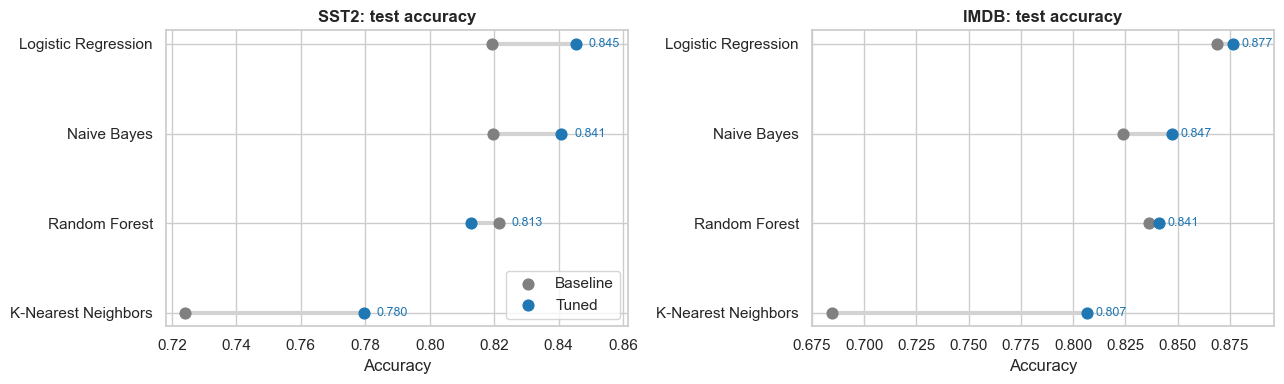

In [9]:
# Dot plot: baseline (grey) -> tuned (blue) test accuracy per model
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ds in zip(axes, clean):
    sub = results[results.Dataset == ds].pivot(index="Model", columns="Setting", values="Accuracy")
    sub = sub.sort_values("Tuned")
    y = np.arange(len(sub))
    ax.hlines(y, sub["Baseline"], sub["Tuned"], color="lightgrey", lw=3)
    ax.scatter(sub["Baseline"], y, color="grey", s=60, label="Baseline", zorder=3)
    ax.scatter(sub["Tuned"], y, color="tab:blue", s=60, label="Tuned", zorder=3)
    for yi, (b, t) in enumerate(zip(sub["Baseline"], sub["Tuned"])):
        ax.text(max(b, t) + 0.004, yi, f"{t:.3f}", va="center", fontsize=9, color="tab:blue")
    ax.set_yticks(y, sub.index)
    ax.set_title(f"{ds}: test accuracy", fontweight="bold")
    ax.set_xlabel("Accuracy")
    ax.set_xlim(right=ax.get_xlim()[1] + 0.01)
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 7. How each hyperparameter affects the CV score
Each dot is one combination tried by the search. Because other parameters vary at the same time, read these as trends, not exact effects.

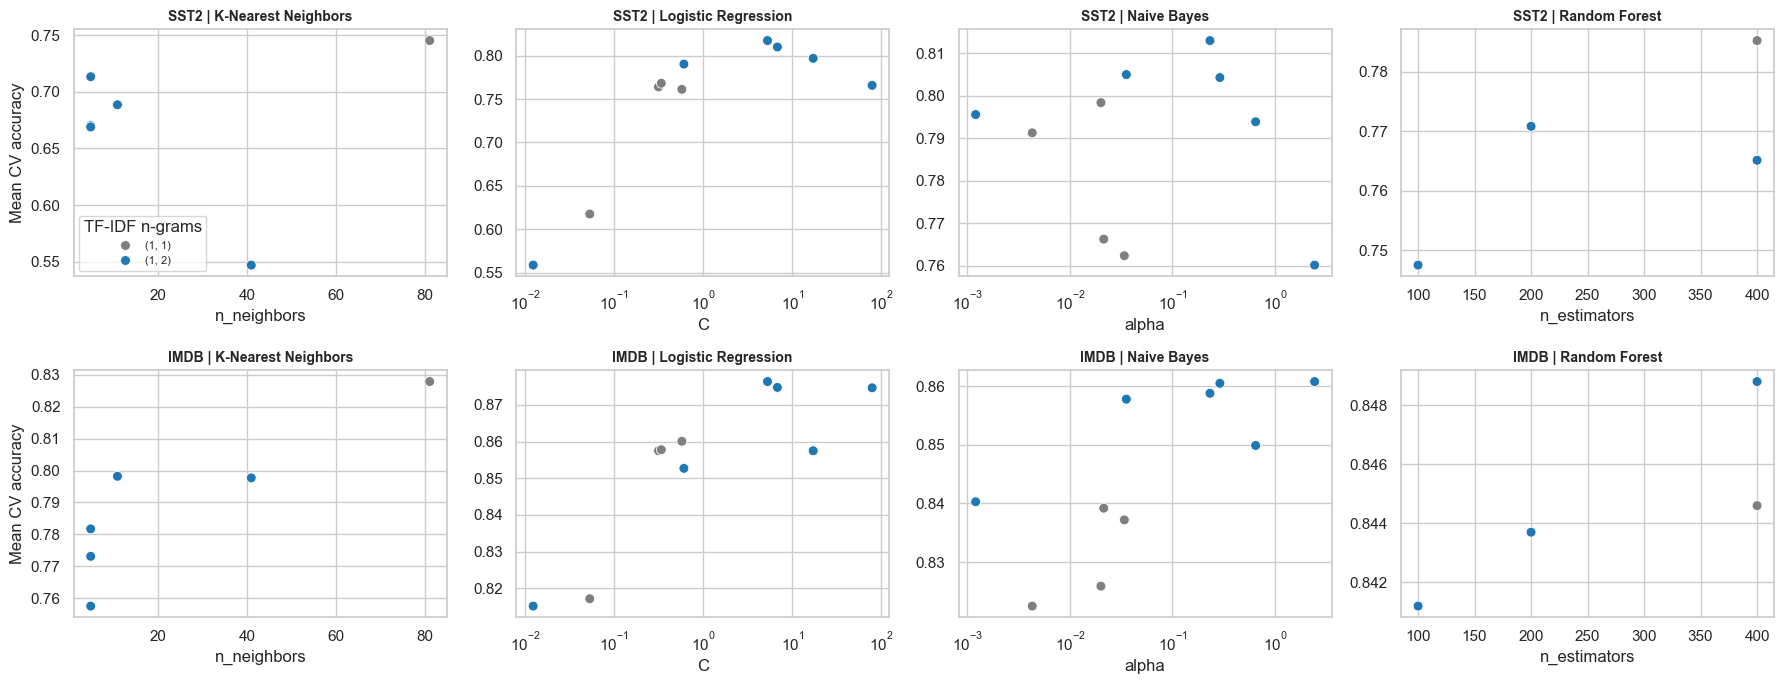

In [10]:
KEY_PARAMS = {
    "K-Nearest Neighbors": ("clf__n_neighbors", False),
    "Logistic Regression": ("clf__C", True),
    "Naive Bayes":         ("clf__alpha", True),
    "Random Forest":       ("clf__n_estimators", False),
}
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for col, (name, (param, logx)) in enumerate(KEY_PARAMS.items()):
    for row, ds in enumerate(clean):
        cvr = pd.DataFrame(searches[(ds, name)].cv_results_)
        ax = axes[row, col]
        hue = cvr["param_tfidf__ngram_range"].astype(str)
        sns.scatterplot(x=cvr[f"param_{param}"].astype(float), y=cvr["mean_test_accuracy"],
                        hue=hue, hue_order=["(1, 1)", "(1, 2)"],
                        palette={"(1, 1)": "tab:grey", "(1, 2)": "tab:blue"},
                        ax=ax, s=50, legend=(row == 0 and col == 0))
        if logx: ax.set_xscale("log")
        ax.set_title(f"{ds} | {name}", fontsize=10, fontweight="bold")
        ax.set_xlabel(param.split("__")[1]); ax.set_ylabel("Mean CV accuracy" if col == 0 else "")
axes[0, 0].legend(title="TF-IDF n-grams", fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
# Top 5 configurations for any model, e.g. Logistic Regression on IMDB
def top_configs(ds, name, k=5):
    cvr = pd.DataFrame(searches[(ds, name)].cv_results_)
    cols = [c for c in cvr if c.startswith("param_")] + ["mean_test_accuracy", "std_test_accuracy", "mean_fit_time"]
    return cvr.sort_values("rank_test_accuracy")[cols].head(k).rename(columns=lambda c: c.replace("param_", "").replace("__", "."))

display(top_configs("IMDB", "Logistic Regression"))

,clf.C,clf.class_weight,tfidf.max_df,tfidf.max_features,tfidf.min_df,tfidf.ngram_range,tfidf.sublinear_tf,mean_test_accuracy,std_test_accuracy,mean_fit_time
7,5.262961,None,0.9,20000,1,"(1, 2)",False,0.8764,0.002002,5.041542
2,6.796578,balanced,0.9,20000,2,"(1, 2)",False,0.8748,0.002084,5.241789
5,78.527555,None,1.0,20000,5,"(1, 2)",True,0.8747,0.001217,5.502872
9,0.576249,None,1.0,5000,5,"(1, 1)",False,0.8601,0.000378,1.183719
6,0.338726,balanced,1.0,5000,5,"(1, 1)",True,0.8578,0.002111,1.324733


## 8. Cross-domain test (the paper's setup): train on SST-2, test on IMDB
The tuned SST-2 pipelines are applied to IMDB reviews they have never seen. This shows how well each model generalizes from short phrases to long reviews.

In [12]:
yte_imdb = data["IMDB"][1]["label"].values
rows = []
for name in MODELS:
    for setting, model in [("Baseline", baseline_fitted[("SST2", name)]),
                           ("Tuned", searches[("SST2", name)].best_estimator_)]:
        s = test_scores(model, clean["IMDB"][1], yte_imdb)
        rows.append({"Model": name, "Setting": setting, **s,
                     "Predicted positive": model.predict(clean["IMDB"][1]).mean()})
cross_df = pd.DataFrame(rows).round(4)
display(cross_df)

,Model,Setting,Accuracy,Precision,Recall,F1-Score,Predicted positive
0,K-Nearest Neighbors,Baseline,0.4944,0.4941,0.4680,0.4807,0.4736
1,K-Nearest Neighbors,Tuned,0.7276,0.7097,0.7704,0.7388,0.5428
2,Logistic Regression,Baseline,0.7892,0.8473,0.7056,0.7700,0.4164
3,Logistic Regression,Tuned,0.7986,0.8493,0.7260,0.7828,0.4274
4,Naive Bayes,Baseline,0.7990,0.8188,0.7680,0.7926,0.4690
5,Naive Bayes,Tuned,0.7936,0.8376,0.7284,0.7792,0.4348
6,Random Forest,Baseline,0.6570,0.7618,0.4568,0.5711,0.2998
7,Random Forest,Tuned,0.7126,0.7042,0.7332,0.7184,0.5206


# 9. Beyond TF-IDF: does the text representation explain the drop on IMDB?

**Question.** In the paper, models trained on SST-2 lose a lot of accuracy on IMDB. Does replacing TF-IDF with representations that capture meaning reduce that drop, and does it change which classifier wins?

**Rule: change only the features.** Same SST-2 training set, same SST-2 and IMDB test sets, same four classifiers, same metrics. Every model is trained on **SST-2 only** and tested on SST-2 (in-domain) and IMDB (cross-domain). The key number is the **drop** = SST-2 accuracy − IMDB accuracy.

| Family | Representations tested | Input text |
|---|---|---|
| Count-based (sparse) | Binary bag of words, TF-IDF (as in the paper), TF-IDF + bigrams, character n-grams | stemmed tokens (char n-grams: raw text) |
| Reduced | LSA: TF-IDF compressed to 300 dimensions with truncated SVD | stemmed tokens |
| Static embeddings (dense) | Word2Vec and FastText trained on SST-2; pretrained GloVe 100d (plain mean and TF-IDF-weighted mean) | lowercase words, no stemming |
| Contextual (dense) | Sentence-BERT `all-MiniLM-L6-v2`; reference: DistilBERT fine-tuned on SST-2 | raw text |

**Notes on the protocol**
- **Naive Bayes:** Multinomial NB needs non-negative features, so dense vectors (LSA, embeddings) use **Gaussian NB**. The `NB variant` column records which one was used.
- **Tuning:** each classifier gets a small grid search (3-fold CV on the SST-2 training set) for each representation, so no representation is judged with settings tuned for another. Random Forest uses fixed settings to keep the run time reasonable.
- **For speed,** each representation is fitted once on the whole SST-2 training set, and the grid search runs on those fixed features. The test sets are never used for fitting.
- **FastText here is trained on SST-2**, so it shows what subword information alone adds over Word2Vec trained on the same data. Pretrained GloVe shows what outside knowledge adds.
- **Run time:** Sentence-BERT and DistilBERT are much faster on a GPU (Colab: *Runtime → Change runtime type → T4 GPU*). Section 9.4 re-runs only the representations that are not finished yet if the cell is interrupted.

In [13]:
%pip install -q "gensim>=4.4" sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [14]:
import torch
from transformers.utils import is_torch_available
print(torch.__version__, is_torch_available())
from sentence_transformers import SentenceTransformer
print("OK")

2.6.0+cu124 True
OK


## 9.1 Settings and text variants

In [15]:
import hashlib
import scipy.sparse as sp
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV

RUN_SBERT      = True    # Sentence-BERT embeddings (GPU recommended)
RUN_DISTILBERT = True    # DistilBERT reference on IMDB (GPU recommended)
GLOVE_NAME     = "glove-wiki-gigaword-100"   # ~130 MB download via gensim
SBERT_NAME     = "all-MiniLM-L6-v2"
RF_TREES       = 200 if FAST_MODE else 400

WORD_RE = re.compile(r"n't|'[a-z]+|[a-z]+")

def words_text(text):
    # for word embeddings: real words, no stemming, stop words kept (GloVe knows "not", "n't").
    # Contractions are split the way SST-2 and GloVe write them: "don't" -> "do n't", "it's" -> "it 's"
    text = HTML.sub(" ", str(text).lower())
    text = re.sub(r"n't\b", " n't", text)
    text = re.sub(r"'(s|re|ve|ll|d|m)\b", r" '\1", text)
    return " ".join(WORD_RE.findall(text))

def raw_text(text):
    # for character n-grams and transformers: natural text, HTML removed
    return re.sub(r"\s+", " ", HTML.sub(" ", str(text))).strip()

splits = {"train": data["SST2"][0], "sst2_test": data["SST2"][1], "imdb_test": data["IMDB"][1]}
y = {k: df["label"].values for k, df in splits.items()}
texts = {
    "stem":  {"train": clean["SST2"][0], "sst2_test": clean["SST2"][1], "imdb_test": clean["IMDB"][1]},
    "words": {k: [words_text(t) for t in df["text"]] for k, df in splits.items()},
    "raw":   {k: [raw_text(t) for t in df["text"]] for k, df in splits.items()},
}
for k in splits:
    print(f"{k:10} n={len(y[k]):,}  mean length = {np.mean([len(t.split()) for t in texts['words'][k]]):.0f} words")
print("\nSame review, three inputs:")
for v in texts:
    print(f"  {v:5}:", texts[v]["imdb_test"][0][:110])

train      n=10,000  mean length = 9 words
sst2_test  n=5,000  mean length = 9 words
imdb_test  n=5,000  mean length = 233 words

Same review, three inputs:
  stem : blockbust saw film call dark harvest cover art look great plot not bad taglin reap sow made movi look pretti g
  words: i was in blockbuster and i saw a film called dark harvest the cover art looked great the plot was n't that bad
  raw  : I was in Blockbuster and I saw a film called "Dark Harvest". The cover art looked great, the plot wasn't that 


## 9.2 Feature extractors
Each extractor has `fit` (learns from the SST-2 training texts only) and `transform` (turns any list of texts into a matrix with one row per text).

In [16]:
class MeanEmbedding(BaseEstimator, TransformerMixin):
    # Average of pretrained word vectors. weighting="tfidf": each word weighted by its IDF learned on the
    # training set (repeated words count several times, so the weight is tf x idf). Unknown words are skipped.
    def __init__(self, kv, weighting="mean"):
        self.kv, self.weighting = kv, weighting
    def fit(self, X, y=None):
        if self.weighting == "tfidf":
            tf = TfidfVectorizer(token_pattern=r"\S+").fit(X)
            self.idf_ = dict(zip(tf.get_feature_names_out(), tf.idf_))
            self.default_idf_ = float(np.max(tf.idf_))     # unseen in training -> treated as rare
        return self
    def transform(self, X):
        out = np.zeros((len(X), self.kv.vector_size), dtype=np.float32)
        for i, doc in enumerate(X):
            toks = [w for w in doc.split() if w in self.kv.key_to_index]
            if not toks:
                continue
            vecs = self.kv[toks]
            if self.weighting == "tfidf":
                w = np.array([self.idf_.get(t, self.default_idf_) for t in toks], dtype=np.float32)
                out[i] = (w[:, None] * vecs).sum(0) / w.sum()
            else:
                out[i] = vecs.mean(0)
        return out


class TrainedEmbedding(BaseEstimator, TransformerMixin):
    # Word2Vec or FastText trained on the training texts, then mean-pooled.
    # FastText builds vectors for unseen words from character n-grams; Word2Vec skips them.
    def __init__(self, kind="word2vec", vector_size=100, window=5, min_count=2, epochs=15):
        self.kind, self.vector_size, self.window, self.min_count, self.epochs = kind, vector_size, window, min_count, epochs
    def fit(self, X, y=None):
        from gensim.models import Word2Vec, FastText
        Model = FastText if self.kind == "fasttext" else Word2Vec
        self.model_ = Model(sentences=[d.split() for d in X], vector_size=self.vector_size, window=self.window,
                            min_count=self.min_count, epochs=self.epochs, sg=1, seed=SEED, workers=4)
        return self
    def transform(self, X):
        wv, out = self.model_.wv, np.zeros((len(X), self.vector_size), dtype=np.float32)
        for i, doc in enumerate(X):
            toks = doc.split() if self.kind == "fasttext" else [w for w in doc.split() if w in wv.key_to_index]
            if toks:
                out[i] = np.mean([wv[w] for w in toks], axis=0)
        return out


class SBERTEncoder(BaseEstimator, TransformerMixin):
    # Frozen Sentence-BERT: one 384-dim vector per text. Cached to disk, so re-runs are instant.
    # Texts longer than the model's limit (256 word pieces for MiniLM) are truncated.
    def __init__(self, model_name=SBERT_NAME, batch_size=64):
        self.model_name, self.batch_size = model_name, batch_size
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        key = hashlib.md5(("\n".join(X) + self.model_name).encode()).hexdigest()[:12]
        path = os.path.join(CACHE_DIR, f"sbert_{key}.npy")
        if os.path.exists(path):
            return np.load(path)
        from sentence_transformers import SentenceTransformer
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        emb = self.model_.encode(list(X), batch_size=self.batch_size, show_progress_bar=True,
                                 convert_to_numpy=True).astype(np.float32)
        np.save(path, emb)
        return emb


_glove = None
def glove():
    global _glove
    if _glove is None:
        import gensim.downloader as api
        print(f"Loading {GLOVE_NAME} ...")
        _glove = api.load(GLOVE_NAME)
    return _glove

# name: (text variant, function that builds a fresh extractor)
REPRESENTATIONS = {
    "BoW (binary)":           ("stem",  lambda: CountVectorizer(token_pattern=r"\S+", binary=True, min_df=2)),
    "TF-IDF (as in paper)":   ("stem",  lambda: TfidfVectorizer(token_pattern=r"\S+")),
    "TF-IDF + bigrams":       ("stem",  lambda: TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2),
                                                                min_df=2, sublinear_tf=True)),
    "Char n-grams (3-5)":     ("raw",   lambda: TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                                                                sublinear_tf=True, max_features=100_000)),
    "LSA (300 dims)":         ("stem",  lambda: Pipeline([("tfidf", TfidfVectorizer(token_pattern=r"\S+", sublinear_tf=True)),
                                                          ("svd", TruncatedSVD(n_components=300, random_state=SEED))])),
    "Word2Vec (SST-2)":       ("words", lambda: TrainedEmbedding("word2vec")),
    "FastText (SST-2)":       ("words", lambda: TrainedEmbedding("fasttext")),
    "GloVe 100d (mean)":      ("words", lambda: MeanEmbedding(glove())),
    "GloVe 100d (TF-IDF wt)": ("words", lambda: MeanEmbedding(glove(), "tfidf")),
    "Sentence-BERT (MiniLM)": ("raw",   lambda: SBERTEncoder()),
}
if not RUN_SBERT:
    REPRESENTATIONS.pop("Sentence-BERT (MiniLM)")
FAMILY = {"BoW (binary)": "Count", "TF-IDF (as in paper)": "Count", "TF-IDF + bigrams": "Count",
          "Char n-grams (3-5)": "Count", "LSA (300 dims)": "Reduced", "Word2Vec (SST-2)": "Static",
          "FastText (SST-2)": "Static", "GloVe 100d (mean)": "Static", "GloVe 100d (TF-IDF wt)": "Static",
          "Sentence-BERT (MiniLM)": "Contextual"}
print(len(REPRESENTATIONS), "representations")

10 representations


## 9.3 Classifiers for each representation
Same four classifiers as before. The grid is small and covers the parameter that mattered most in section 7.

In [17]:
def classifiers(X):
    sparse = sp.issparse(X)
    nonneg = (X.min() >= 0) if sparse else bool((X >= 0).all())
    scale = [] if sparse else [("scale", StandardScaler())]          # dense features: standardise for LR
    if nonneg:
        nb, nb_grid, nb_name = MultinomialNB(), {"clf__alpha": [0.1, 0.5, 1.0]}, "Multinomial"
    else:
        nb, nb_grid, nb_name = GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-6, 1e-3]}, "Gaussian"
    return nb_name, {
        "K-Nearest Neighbors": (Pipeline([("clf", KNeighborsClassifier(metric="cosine", weights="distance"))]),
                                {"clf__n_neighbors": [5, 21, 81]}),
        "Logistic Regression": (Pipeline(scale + [("clf", LogisticRegression(max_iter=3000))]),
                                {"clf__C": [0.1, 1.0, 10.0]}),
        "Naive Bayes":         (Pipeline([("clf", nb)]), nb_grid),
        "Random Forest":       (Pipeline([("clf", RandomForestClassifier(n_estimators=RF_TREES, max_features="sqrt",
                                                                         random_state=SEED, n_jobs=N_JOBS))]), None),
    }

## 9.4 Run the comparison (slow cell)
Results are kept in `rep_rows`. If the cell is interrupted, run it again: finished representations are skipped.

In [18]:
if "rep_rows" not in globals():
    rep_rows, rep_models = [], {}
done = {r["Representation"] for r in rep_rows}
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

for rep_name, (variant, make) in REPRESENTATIONS.items():
    if rep_name in done:
        continue
    t0 = time.time()
    extractor = make()
    X_tr = extractor.fit_transform(texts[variant]["train"])
    X_sst = extractor.transform(texts[variant]["sst2_test"])
    X_imdb = extractor.transform(texts[variant]["imdb_test"])
    feat_time = time.time() - t0
    nb_name, clfs = classifiers(X_tr)
    print(f"\n{rep_name}: {X_tr.shape[1]:,} dims, {'sparse' if sp.issparse(X_tr) else 'dense'}, "
          f"features in {feat_time:.0f}s")

    for clf_name, (pipe, grid) in clfs.items():
        t1 = time.time()
        if grid:
            search = GridSearchCV(pipe, grid, cv=cv3, scoring="accuracy", n_jobs=N_JOBS).fit(X_tr, y["train"])
            model, best = search.best_estimator_, {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
        else:
            model, best = clone(pipe).fit(X_tr, y["train"]), {}
        s_in, s_out = test_scores(model, X_sst, y["sst2_test"]), test_scores(model, X_imdb, y["imdb_test"])
        rep_models[(rep_name, clf_name)] = model
        rep_rows.append({
            "Representation": rep_name, "Family": FAMILY[rep_name], "Model": clf_name,
            "NB variant": nb_name if clf_name == "Naive Bayes" else "",
            "Dims": X_tr.shape[1], "SST2 acc": s_in["Accuracy"], "IMDB acc": s_out["Accuracy"],
            "SST2 F1": s_in["F1-Score"], "IMDB F1": s_out["F1-Score"],
            "Drop": s_in["Accuracy"] - s_out["Accuracy"],
            "IMDB predicted positive": model.predict(X_imdb).mean(),
            "Best params": best, "Feature time (s)": feat_time, "Fit time (s)": time.time() - t1,
        })
        r = rep_rows[-1]
        print(f"   {clf_name:20} SST-2 {r['SST2 acc']:.3f} | IMDB {r['IMDB acc']:.3f} | drop {r['Drop']:+.3f}  {best}")

rep_df = pd.DataFrame(rep_rows)
rep_df.drop(columns=["Best params"]).to_csv("results_representations.csv", index=False)
print("\nSaved results_representations.csv")


BoW (binary): 4,706 dims, sparse, features in 0s
   K-Nearest Neighbors  SST-2 0.809 | IMDB 0.593 | drop +0.216  {'n_neighbors': 5}
   Logistic Regression  SST-2 0.822 | IMDB 0.790 | drop +0.032  {'C': 1.0}
   Naive Bayes          SST-2 0.814 | IMDB 0.782 | drop +0.032  {'alpha': 1.0}
   Random Forest        SST-2 0.817 | IMDB 0.762 | drop +0.055  {}

TF-IDF (as in paper): 6,889 dims, sparse, features in 0s
   K-Nearest Neighbors  SST-2 0.830 | IMDB 0.598 | drop +0.231  {'n_neighbors': 5}
   Logistic Regression  SST-2 0.840 | IMDB 0.785 | drop +0.055  {'C': 10.0}
   Naive Bayes          SST-2 0.833 | IMDB 0.794 | drop +0.039  {'alpha': 0.5}
   Random Forest        SST-2 0.822 | IMDB 0.669 | drop +0.153  {}

TF-IDF + bigrams: 13,695 dims, sparse, features in 1s
   K-Nearest Neighbors  SST-2 0.822 | IMDB 0.663 | drop +0.159  {'n_neighbors': 5}
   Logistic Regression  SST-2 0.839 | IMDB 0.806 | drop +0.033  {'C': 10.0}
   Naive Bayes          SST-2 0.830 | IMDB 0.801 | drop +0.029  {'alp

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (8 outputs left out)

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]


Sentence-BERT (MiniLM): 384 dims, dense, features in 33s
   K-Nearest Neighbors  SST-2 0.836 | IMDB 0.669 | drop +0.167  {'n_neighbors': 21}
   Logistic Regression  SST-2 0.837 | IMDB 0.737 | drop +0.100  {'C': 0.1}
   Naive Bayes          SST-2 0.822 | IMDB 0.717 | drop +0.105  {'var_smoothing': 1e-09}
   Random Forest        SST-2 0.841 | IMDB 0.722 | drop +0.118  {}

Saved results_representations.csv


## 9.5 Reference: DistilBERT fine-tuned on SST-2, tested on IMDB
This model (`distilbert-base-uncased-finetuned-sst-2-english`) is fine-tuned end to end, so it is a ceiling to compare against, not part of the four-classifier comparison.

**Only its IMDB score is valid here.** It was fine-tuned on the full SST-2 training split, which contains our SST-2 test sentences, so its SST-2 score would be inflated. Without a GPU it is run on a random 1,000 IMDB reviews to save time.

In [19]:
distil_imdb_acc = None
if RUN_DISTILBERT:
    import torch
    from transformers import pipeline as hf_pipeline
    gpu = torch.cuda.is_available()
    sent = hf_pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english",
                       device=0 if gpu else -1, truncation=True, max_length=512)
    X, yy = texts["raw"]["imdb_test"], y["imdb_test"]
    if not gpu:
        idx = np.random.RandomState(SEED).choice(len(X), min(1000, len(X)), replace=False)
        X, yy = [X[i] for i in idx], yy[idx]
    t0 = time.time()
    preds = np.array([1 if p["label"] == "POSITIVE" else 0 for p in sent(X, batch_size=32)])
    distil_imdb_acc = accuracy_score(yy, preds)
    print(f"DistilBERT (SST-2 fine-tuned) on {len(X):,} IMDB reviews: accuracy {distil_imdb_acc:.3f}, "
          f"F1 {f1_score(yy, preds):.3f}  ({time.time() - t0:.0f}s, {'GPU' if gpu else 'CPU'})")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

DistilBERT (SST-2 fine-tuned) on 5,000 IMDB reviews: accuracy 0.894, F1 0.890  (111s, GPU)


## 9.6 Results

In [20]:
order = (rep_df.groupby("Representation")["IMDB acc"].max().sort_values(ascending=False).index.tolist())
models_order = ["K-Nearest Neighbors", "Logistic Regression", "Naive Bayes", "Random Forest"]

summary = rep_df.pivot(index="Representation", columns="Model", values="IMDB acc").loc[order, models_order]
summary.insert(0, "Family", rep_df.groupby("Representation")["Family"].first().loc[order])
summary["Dims"] = rep_df.groupby("Representation")["Dims"].first().loc[order]
summary["Feature time (s)"] = rep_df.groupby("Representation")["Feature time (s)"].first().loc[order].round(0)
print("IMDB accuracy (cross-domain), every model trained on SST-2 only")
display(summary.round(3))

best = rep_df.loc[rep_df.groupby("Representation")["IMDB acc"].idxmax()].set_index("Representation").loc[order]
print("Best classifier per representation")
display(best[["Model", "SST2 acc", "IMDB acc", "Drop", "IMDB predicted positive"]].round(3))

IMDB accuracy (cross-domain), every model trained on SST-2 only


Model,Family,K-Nearest Neighbors,Logistic Regression,Naive Bayes,Random Forest,Dims,Feature time (s)
Representation,,,,,,,
TF-IDF + bigrams,Count,0.663,0.806,0.801,0.698,13695,1.0
TF-IDF (as in paper),Count,0.598,0.785,0.794,0.669,6889,0.0
BoW (binary),Count,0.593,0.790,0.782,0.762,4706,0.0
LSA (300 dims),Reduced,0.667,0.777,0.585,0.636,300,2.0
Char n-grams (3-5),Count,0.645,0.742,0.753,0.686,30358,8.0
Sentence-BERT (MiniLM),Contextual,0.669,0.737,0.717,0.722,384,33.0
GloVe 100d (TF-IDF wt),Static,0.556,0.719,0.502,0.620,100,4.0
GloVe 100d (mean),Static,0.647,0.714,0.500,0.627,100,42.0
FastText (SST-2),Static,0.544,0.651,0.500,0.604,100,10.0


Best classifier per representation


,Model,SST2 acc,IMDB acc,Drop,IMDB predicted positive
Representation,,,,,
TF-IDF + bigrams,Logistic Regression,0.839,0.806,0.033,0.443
TF-IDF (as in paper),Naive Bayes,0.833,0.794,0.039,0.460
BoW (binary),Logistic Regression,0.822,0.790,0.032,0.411
LSA (300 dims),Logistic Regression,0.742,0.777,-0.035,0.546
Char n-grams (3-5),Naive Bayes,0.824,0.753,0.071,0.312
Sentence-BERT (MiniLM),Logistic Regression,0.837,0.737,0.100,0.382
GloVe 100d (TF-IDF wt),Logistic Regression,0.792,0.719,0.073,0.343
GloVe 100d (mean),Logistic Regression,0.789,0.714,0.076,0.324
FastText (SST-2),Logistic Regression,0.681,0.651,0.030,0.301


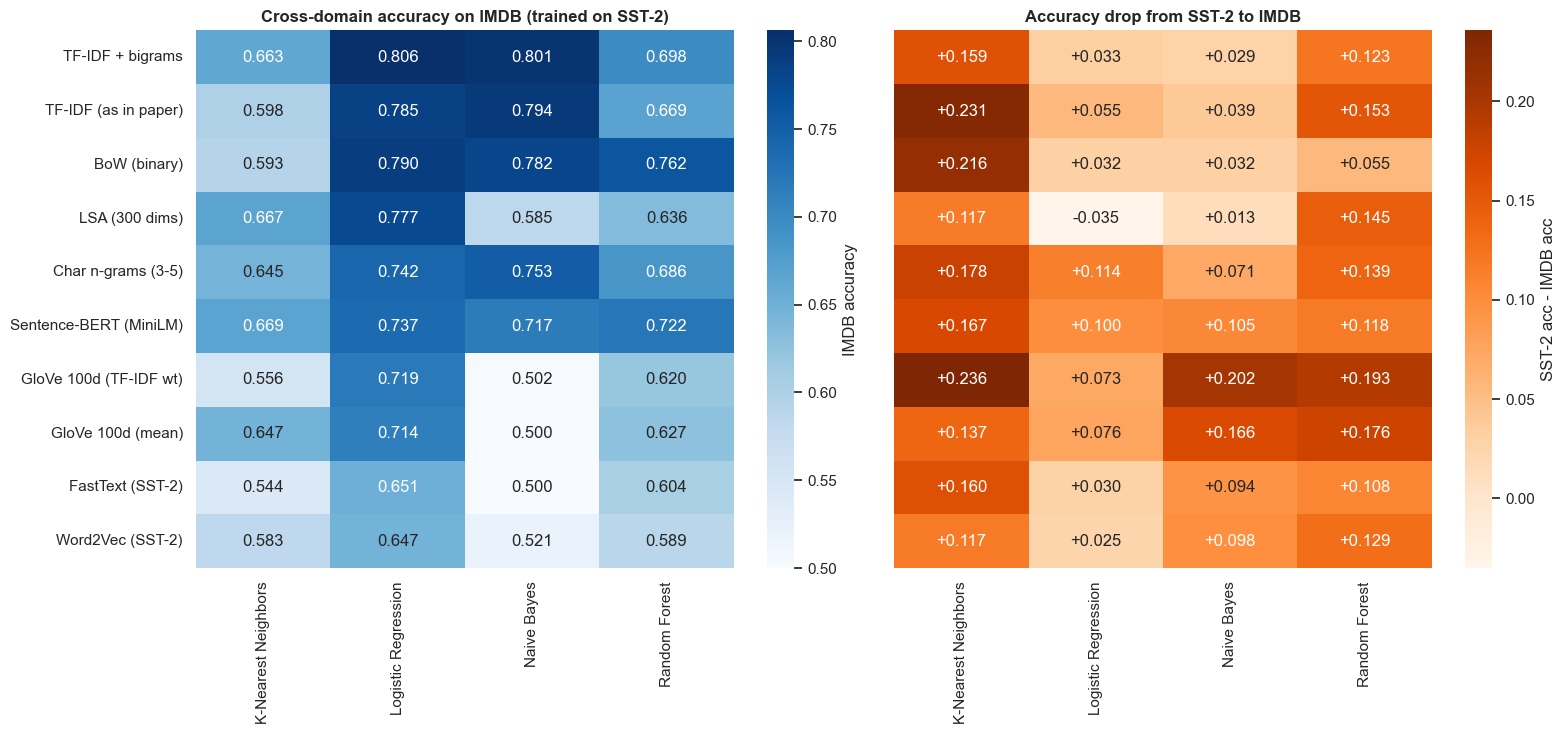

In [21]:
# Heatmaps: IMDB accuracy (higher is better) and drop from SST-2 to IMDB (lower is better)
fig, axes = plt.subplots(1, 2, figsize=(16, 0.55 * len(order) + 2))
acc = rep_df.pivot(index="Representation", columns="Model", values="IMDB acc").loc[order, models_order]
drop = rep_df.pivot(index="Representation", columns="Model", values="Drop").loc[order, models_order]
sns.heatmap(acc, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "IMDB accuracy"}, ax=axes[0])
sns.heatmap(drop, annot=True, fmt="+.3f", cmap="Oranges", cbar_kws={"label": "SST-2 acc - IMDB acc"}, ax=axes[1])
axes[0].set_title("Cross-domain accuracy on IMDB (trained on SST-2)", fontweight="bold")
axes[1].set_title("Accuracy drop from SST-2 to IMDB", fontweight="bold")
axes[1].set_yticklabels([])
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

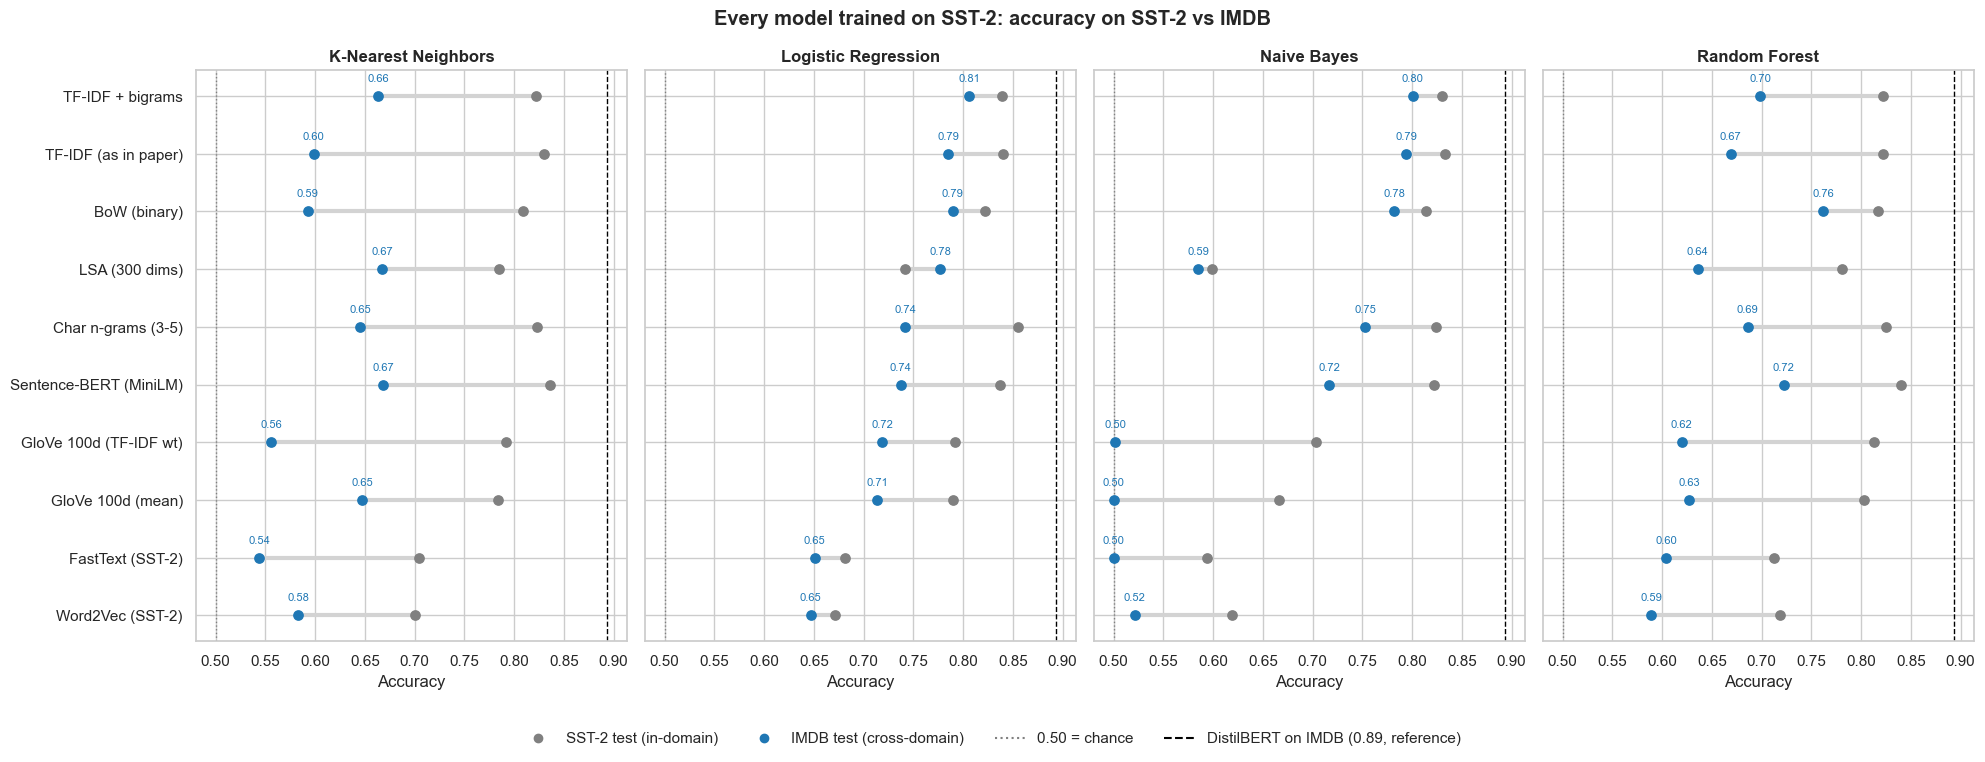

In [22]:
# Dumbbell per classifier: SST-2 accuracy (grey) -> IMDB accuracy (blue); dashed line = DistilBERT on IMDB
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 4, figsize=(20, 0.5 * len(order) + 2.5), sharey=True, sharex=True)
ypos = np.arange(len(order))[::-1]
for ax, m in zip(axes, models_order):
    sub = rep_df[rep_df.Model == m].set_index("Representation").loc[order]
    ax.hlines(ypos, sub["IMDB acc"], sub["SST2 acc"], color="lightgrey", lw=3)
    ax.scatter(sub["SST2 acc"], ypos, color="grey", s=45, zorder=3)
    ax.scatter(sub["IMDB acc"], ypos, color="tab:blue", s=45, zorder=3)
    for yi, v in zip(ypos, sub["IMDB acc"]):
        ax.text(v, yi + 0.25, f"{v:.2f}", ha="center", fontsize=8, color="tab:blue")
    if distil_imdb_acc is not None:
        ax.axvline(distil_imdb_acc, ls="--", color="black", lw=1)
    ax.axvline(0.5, ls=":", color="grey", lw=1)
    ax.set_title(m, fontweight="bold"); ax.set_xlabel("Accuracy")
axes[0].set_yticks(ypos, order)
handles = [Line2D([], [], marker="o", ls="", color="grey", label="SST-2 test (in-domain)"),
           Line2D([], [], marker="o", ls="", color="tab:blue", label="IMDB test (cross-domain)"),
           Line2D([], [], ls=":", color="grey", label="0.50 = chance")]
if distil_imdb_acc is not None:
    handles.append(Line2D([], [], ls="--", color="black", label=f"DistilBERT on IMDB ({distil_imdb_acc:.2f}, reference)"))
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Every model trained on SST-2: accuracy on SST-2 vs IMDB", fontweight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

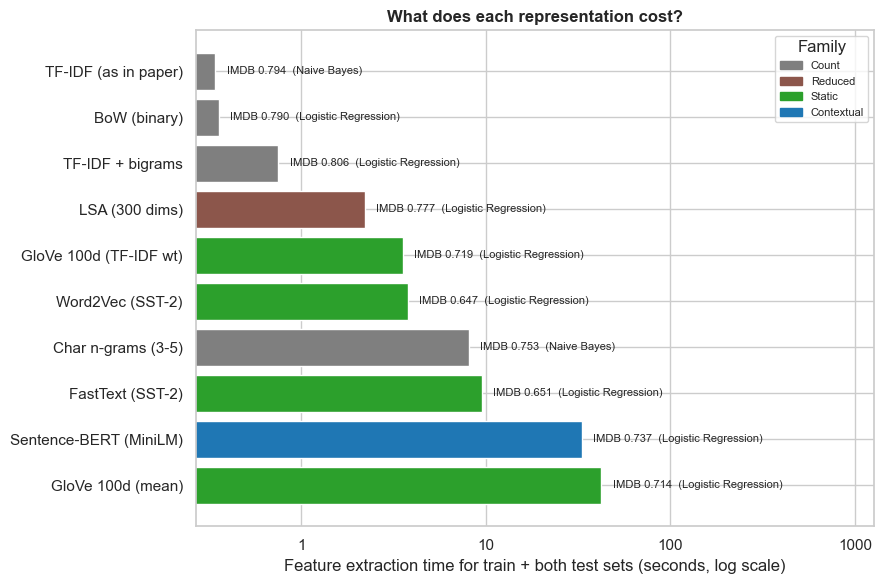

In [23]:
# Cost vs benefit: feature-extraction time per representation, with its best IMDB accuracy at the bar end
fam_colors = {"Count": "tab:grey", "Reduced": "tab:brown", "Static": "tab:green", "Contextual": "tab:blue"}
cost = best.assign(t=best["Feature time (s)"].clip(lower=0.1)).sort_values("t")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(cost) + 1.5))
ax.barh(cost.index, cost["t"], color=[fam_colors[FAMILY[n]] for n in cost.index])
for i, (n, r) in enumerate(cost.iterrows()):
    ax.text(r["t"] * 1.15, i, f"IMDB {r['IMDB acc']:.3f}  ({r['Model']})", va="center", fontsize=8)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlim(right=cost["t"].max() * 30)
ax.invert_yaxis()
ax.set_xlabel("Feature extraction time for train + both test sets (seconds, log scale)")
ax.set_title("What does each representation cost?", fontweight="bold")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f) for f, c in fam_colors.items()],
          title="Family", fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 9.7 Why: how many IMDB words does each representation know?
A model trained on SST-2 can only use IMDB words that its representation knows. This measures the vocabulary gap behind hypothesis H2.

In [24]:
def coverage(tokens_docs, known):
    toks = [t for d in tokens_docs for t in d.split()]
    return np.mean([t in known for t in toks])

tfidf_vocab = set(TfidfVectorizer(token_pattern=r"\S+").fit(texts["stem"]["train"]).vocabulary_)
w2v_vocab = set(TrainedEmbedding("word2vec").fit(texts["words"]["train"]).model_.wv.key_to_index)
cov = {
    "TF-IDF vocabulary (stemmed SST-2 words)": coverage(texts["stem"]["imdb_test"], tfidf_vocab),
    "Word2Vec trained on SST-2":               coverage(texts["words"]["imdb_test"], w2v_vocab),
    "GloVe 100d (pretrained, 400k words)":     coverage(texts["words"]["imdb_test"], glove().key_to_index),
    "FastText / char n-grams / Sentence-BERT": 1.0,
}
display(pd.Series(cov, name="Share of IMDB word occurrences covered").round(3).to_frame())
print("FastText, character n-grams and Sentence-BERT build a representation for any word from its pieces.")

,Share of IMDB word occurrences covered
TF-IDF vocabulary (stemmed SST-2 words),0.860
Word2Vec trained on SST-2,0.869
"GloVe 100d (pretrained, 400k words)",0.995
FastText / char n-grams / Sentence-BERT,1.000


FastText, character n-grams and Sentence-BERT build a representation for any word from its pieces.
